# Étape 2 : Compréhension des données et analyse exploratoire

**Projet Python for AI - M1 ISA**
Jeu de données : *Bank Marketing*, UCI Machine Learning Repository (n° 222).
Référence : Moro, S., Cortez, P., & Rita, P. (2014). *A data-driven approach to
predict the success of bank telemarketing.* Decision Support Systems, 62, 22-31.

---

**Méthode :** Reprise de la chaîne de traitement de la correction du TD2 :

1.`load_and_preview`  
2.`analyze_missing_values`   
3.`analyze_distributions`  
4.`display_outliers`  
5.`analyze_class_balance`

Deux fonctions sont ajoutées, parce que le jeu *Bank Marketing* contient des
variables catégorielles :
`analyze_categorical` et `analyze_target_relation`.

**Périmètre :** L'énoncé du projet réserve l'étude multivariée à l'étape 3. Ce
notebook s'arrête donc à l'univarié et au bivarié. Les corrélations, la
normalisation, le traitement des manquants et le rééquilibrage sont traités dans
le notebook `02_preparation`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from outils import bold, cyan, print_title, print_step

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid')

FICHIER = '../data/bank-additional-full.csv'
DOSSIER_FIGURES = '../figures/'

TARGET_COL = 'y'

# La durée de l'appel n'est connue qu'APRÈS l'appel : les auteurs du jeu signalent
# explicitement qu'elle doit être écartée d'un modèle réaliste. Elle est conservée
# dans l'exploration pour pouvoir justifier son exclusion, puis retirée.
FUITE_COL = 'duration'

## 1. Chargement et aperçu

Le séparateur du fichier est un point-virgule.

In [2]:
def load_and_preview(file_path):
    """
    Charge le fichier CSV et affiche les informations de base
    """
    df = pd.read_csv(
        filepath_or_buffer=file_path,
        delimiter=';')
    # Infos
    print_title(file_path)
    print_step('Informations de base')
    # Affichage des dimensions
    print(f"Dimensions du dataset : {df.shape}")
    # Infos sur les colonnes
    print("\n" + bold('Informations sur les colonnes :'))
    print(df.info())
    # Aperçu des données
    print("\n" + bold('Aperçu des données :'))
    print(df.head(10))
    return df


df = load_and_preview(FICHIER)


--------------------------------------------------------------------------------
Fichier : : ../data/bank-additional-full.csv
--------------------------------------------------------------------------------

*** Informations de base ***

Dimensions du dataset : (41188, 21)

Informations sur les colonnes :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64 

## 2. Valeurs manquantes

On applique d'abord le test standard, `df.isna()`.

In [3]:
def analyze_missing_values(df):
    """
    Analyse et visualise les valeurs manquantes
    """
    # Calcul des valeurs manquantes
    missing_values = df.isna().sum()
    missing_percent = (missing_values / len(df)) * 100
    # Affichage des résultats
    print_step('Traitement des valeurs manquantes')
    print(bold('Nombre de valeurs manquantes par variable :'))
    print(missing_values)
    print("\n" + bold('Total : ') + str(missing_values.sum()))
    return missing_values, missing_percent


missing_values, missing_percent = analyze_missing_values(df)


*** Traitement des valeurs manquantes ***

Nombre de valeurs manquantes par variable :
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

Total : 0


**`isna()` ne détecte aucune valeur manquante.** La conclusion serait pourtant
fausse : dans ce jeu, les valeurs manquantes sont encodées par la chaîne de
caractères `"unknown"`. Elles sont donc invisibles aux fonctions de pandas.

C'est le premier constat méthodologique du projet, et il faut le vérifier.

In [4]:
unknown_count = (df == 'unknown').sum()
unknown_count

age                  0
job                330
marital             80
education         1731
default           8597
housing            990
loan               990
contact              0
month                0
day_of_week          0
duration             0
campaign             0
pdays                0
previous             0
poutcome             0
emp.var.rate         0
cons.price.idx       0
cons.conf.idx        0
euribor3m            0
nr.employed          0
y                    0
dtype: int64

In [5]:
unknown_count = unknown_count[unknown_count > 0].sort_values(ascending=True)
unknown_count

marital        80
job           330
loan          990
housing       990
education    1731
default      8597
dtype: int64

In [6]:
unknown_count.dtype

dtype('int64')

In [7]:
len(df)

41188

In [8]:
unknown_percent = (unknown_count / len(df)) * 100
unknown_percent

marital       0.194231
job           0.801204
loan          2.403613
housing       2.403613
education     4.202680
default      20.872584
dtype: float64


*** Recherche des manquants déguisés en modalité 'unknown' ***

Variables contenant la modalité 'unknown' :
           manquants  pourcentage
default         8597        20.87
education       1731         4.20
housing          990         2.40
loan             990         2.40
job              330         0.80
marital           80         0.19


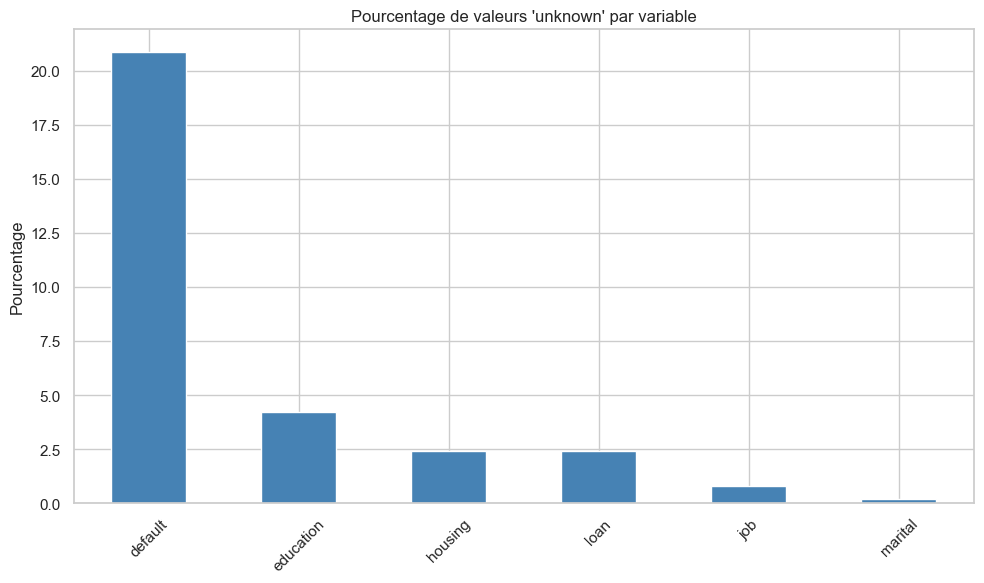

Fichier ../figures/manquants_unknown.png enregistré.


In [9]:
def analyze_unknown_values(df, fig_name, transparent=False):
    """
    Recherche les valeurs manquantes encodées sous forme de modalité 'unknown'
    et les visualise, à la manière du graphe de valeurs manquantes du TD2
    """
    print_step("Recherche des manquants déguisés en modalité 'unknown'")

    unknown_count = (df == 'unknown').sum()
    unknown_count = unknown_count[unknown_count > 0].sort_values(ascending=False)
    unknown_percent = (unknown_count / len(df)) * 100

    resume = pd.DataFrame({
        'manquants': unknown_count,
        'pourcentage': unknown_percent.round(2)})
    print(bold("Variables contenant la modalité 'unknown' :"))
    print(resume)

    # Visualisation
    plt.figure(figsize=(10, 6))
    unknown_percent.plot(kind='bar', color='steelblue')
    plt.title("Pourcentage de valeurs 'unknown' par variable")
    plt.ylabel('Pourcentage')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(fig_name, dpi=100, transparent=transparent)
    plt.show()
    print(f'Fichier {fig_name} enregistré.')
    return resume


resume_unknown = analyze_unknown_values(df, DOSSIER_FIGURES + 'manquants_unknown.png')

Six variables sont concernées. `default` est la plus touchée.

**Aucune imputation n'est faite ici.** Le choix entre imputer et traiter
`"unknown"` comme une modalité à part entière appartient à l'étape 3 ; il sera
argumenté variable par variable.

### La variable `pdays`

`pdays` indique le nombre de jours écoulés depuis le dernier contact d'une
campagne précédente. La documentation du jeu (`bank-additional-names.txt`)
précise que **999 signifie « client jamais contacté auparavant »**.

Cette variable est la seule des trois variables d'historique dont la grandeur
n'a aucun sens en l'absence de contact précédent : « nombre de jours depuis le
dernier contact » n'admet pas de réponse numérique s'il n'y a pas eu de dernier
contact. La sentinelle n'est donc pas un défaut de saisie, c'est une nécessité
sémantique.

Les deux autres variables d'historique mesurent autre chose : `previous` compte
les contacts (la fréquence), `poutcome` donne leur résultat, mais toutes deux
encodent par effet de bord le même fait dérivé : *ce client a-t-il déjà été
contacté ?* (`previous = 0`, `poutcome = nonexistent`).

Elles fournissent donc deux contrôles indépendants de l'interprétation de la
sentinelle. Si 999 signifie bien « jamais contacté », les trois proportions
doivent coïncider.

In [10]:
(df.pdays == 999).sum()/41188 # == (df.pdays == 999).mean()

np.float64(0.9632174419733903)

In [11]:
print_step('Contrôle de cohérence de la sentinelle pdays = 999')
print(bold('Proportion de pdays = 999             : ')
      + f"{100 * (df.pdays == 999).mean():.2f} %")
print(bold("Proportion de poutcome = 'nonexistent' : ")
      + f"{100 * (df.poutcome == 'nonexistent').mean():.2f} %")
print(bold('Proportion de previous = 0            : ')
      + f"{100 * (df.previous == 0).mean():.2f} %")
print("\n" + bold('Distribution de pdays, sentinelle exclue :'))
print(df.loc[df.pdays != 999, 'pdays'].describe())


*** Contrôle de cohérence de la sentinelle pdays = 999 ***

Proportion de pdays = 999             : 96.32 %
Proportion de poutcome = 'nonexistent' : 86.34 %
Proportion de previous = 0            : 86.34 %

Distribution de pdays, sentinelle exclue :
count    1515.000000
mean        6.014521
std         3.824906
min         0.000000
25%         3.000000
50%         6.000000
75%         7.000000
max        27.000000
Name: pdays, dtype: float64


**Le contrôle échoue.** `poutcome` et `previous` s'accordent exactement
(86,34 %), mais `pdays = 999` concerne 96,32 % des lignes : **dix points
d'écart**, soit environ 4 100 clients. La sentinelle ne peut donc pas signifier
seulement « jamais contacté ». Le croisement identifie ces clients.

In [12]:
print_step('Croisement de la sentinelle avec les deux autres variables')

tableau = pd.crosstab(df.pdays == 999, df.poutcome)
tableau.index = ['pdays renseigné', 'pdays = 999']
print(bold('pdays (sentinelle) × poutcome :'))
print(tableau)

incoherents = (df.pdays == 999) & (df.previous >= 1)
print("\n" + bold('Clients déjà contactés (previous ≥ 1) mais pdays = 999 : ')
      + f'{int(incoherents.sum())}')

print("\n" + bold("Identité vérifiée : previous == 0  ⟺  poutcome == 'nonexistent'"))
print('  désaccords : '
      + f"{int(((df.previous == 0) != (df.poutcome == 'nonexistent')).sum())}")

print("\n" + bold('Taux de souscription des trois groupes réels :'))
groupes = [
    (df.pdays != 999, 'Recontacté, délai connu'),
    (incoherents, 'Recontacté, délai inconnu'),
    (df.previous == 0, 'Jamais contacté'),
]
for masque, libelle in groupes:
    sous = df[masque]
    print(f'  {libelle:28s} n = {len(sous):6d}   '
          + f'taux = {100 * (sous[TARGET_COL] == "yes").mean():5.2f} %')


*** Croisement de la sentinelle avec les deux autres variables ***

pdays (sentinelle) × poutcome :
poutcome         failure  nonexistent  success
pdays renseigné      142            0     1373
pdays = 999         4110        35563        0

Clients déjà contactés (previous ≥ 1) mais pdays = 999 : 4110

Identité vérifiée : previous == 0  ⟺  poutcome == 'nonexistent'
  désaccords : 0

Taux de souscription des trois groupes réels :
  Recontacté, délai connu      n =   1515   taux = 63.83 %
  Recontacté, délai inconnu    n =   4110   taux = 12.94 %
  Jamais contacté              n =  35563   taux =  8.83 %


La sentinelle 999 recouvre **deux situations incompatibles** :

- *indéfini* — il n'y a rien à mesurer (35 563 clients, `previous = 0`) ;
- *inconnu* — il y a eu un contact précédent, donc la grandeur existe, mais
  elle n'est pas renseignée (4 110 clients, `previous ≥ 1`,
  `poutcome = failure`).

Les trois groupes réels ont des taux de souscription nettement distincts et
ordonnés : **63,83 %**, **12,94 %** et **8,83 %**. Les confondre détruirait de
l'information.

Deux conséquences pour l'étape 3 :

1. **L'indicateur « déjà contacté » doit être construit sur `previous`, pas sur
   `pdays`.** `previous == 0` coïncide exactement avec
   `poutcome == 'nonexistent'` (aucun désaccord sur 41 188 lignes), alors que
   `pdays != 999` rangerait 4 110 clients déjà contactés du côté « jamais
   contacté ».
2. `pdays` se recode en **trois modalités** (délai connu / délai inconnu / sans
   objet), et non en un binaire accompagné de la durée.

À noter également : les 1 373 `poutcome = success` ont **tous** un `pdays`
renseigné, et représentent 90,6 % des `pdays` renseignés. `pdays != 999` est
donc quasi colinéaire avec `poutcome == 'success'`. Il faudra en tenir compte à
la lecture des importances de variables, sans quoi le signal apparaîtra partagé
entre deux variables qui disent la même chose.

## 3. Statistiques descriptives et distributions

Reprise de `analyze_distributions` du TD2 : `describe()`, puis un histogramme et
une boîte à moustaches par variable numérique.


*** Statistiques descriptives ***

               age      duration      campaign         pdays      previous  emp.var.rate  cons.price.idx  cons.conf.idx     euribor3m   nr.employed
count  41188.00000  41188.000000  41188.000000  41188.000000  41188.000000  41188.000000    41188.000000   41188.000000  41188.000000  41188.000000
mean      40.02406    258.285010      2.567593    962.475454      0.172963      0.081886       93.575664     -40.502600      3.621291   5167.035911
std       10.42125    259.279249      2.770014    186.910907      0.494901      1.570960        0.578840       4.628198      1.734447     72.251528
min       17.00000      0.000000      1.000000      0.000000      0.000000     -3.400000       92.201000     -50.800000      0.634000   4963.600000
25%       32.00000    102.000000      1.000000    999.000000      0.000000     -1.800000       93.075000     -42.700000      1.344000   5099.100000
50%       38.00000    180.000000      2.000000    999.000000      0.000000  

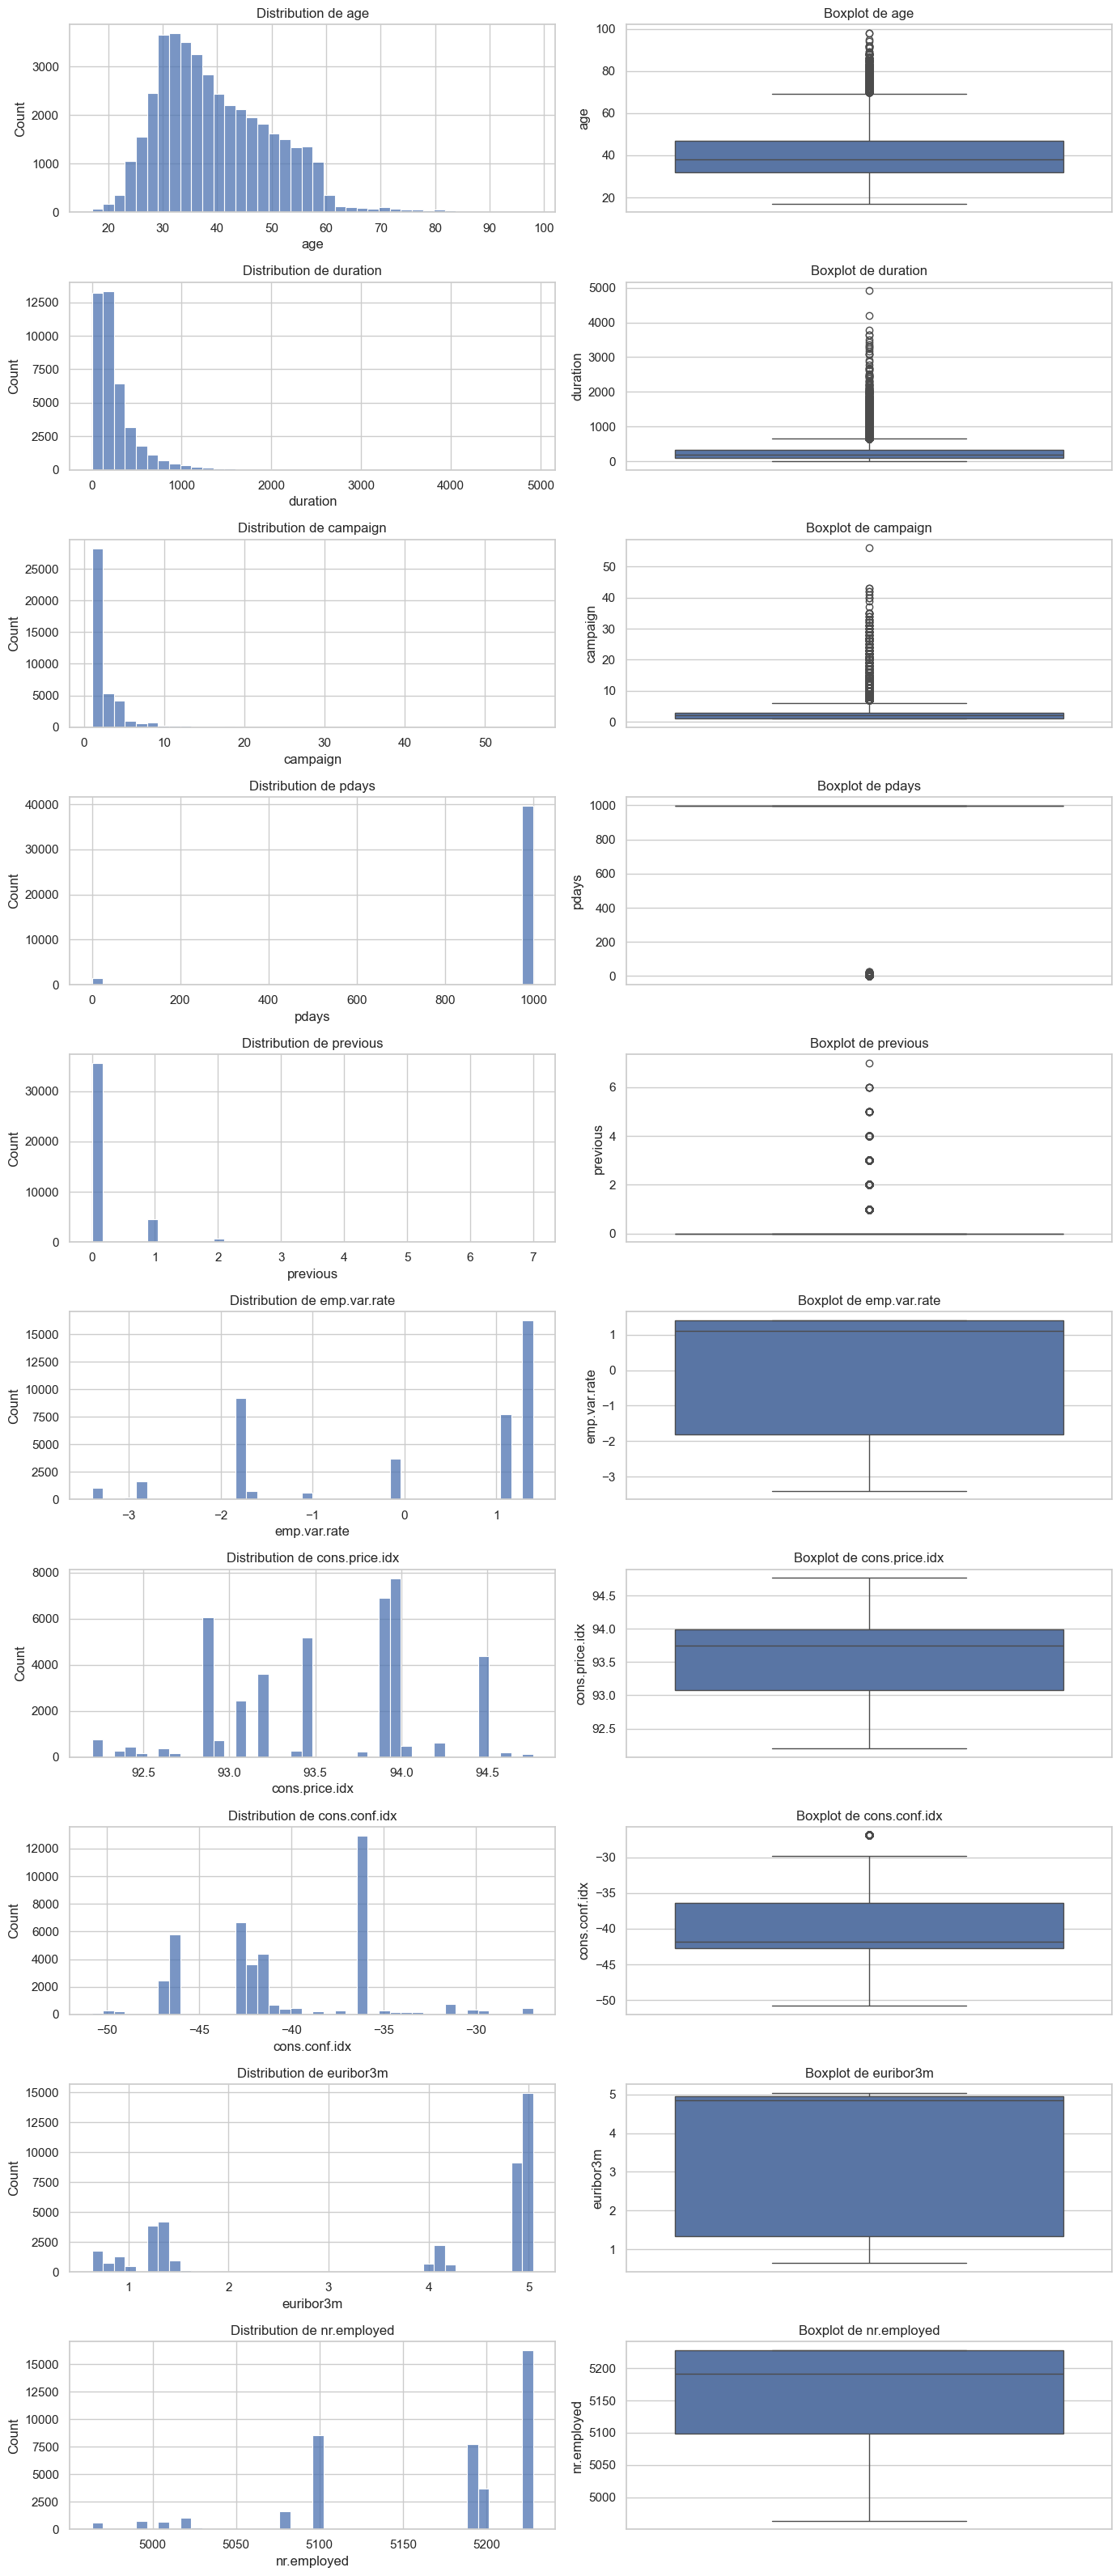

Fichier ../figures/distributions.png enregistré.


In [13]:
def analyze_distributions(df, fig_name, transparent=False):
    """
    Visualise la distribution de chaque variable numérique
    """
    # Statistiques descriptives
    print_step('Statistiques descriptives')
    print(df.describe())

    # Visualisation des distributions
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    n_cols = len(numeric_cols)

    fig, axes = plt.subplots(n_cols, 2, figsize=(14, 3.2 * n_cols))
    for i, col in enumerate(numeric_cols):
        # Histogramme
        sns.histplot(data=df, x=col, ax=axes[i, 0], bins=40)
        axes[i, 0].set_title(f'Distribution de {col}')
        # Boxplot
        sns.boxplot(data=df, y=col, ax=axes[i, 1])
        axes[i, 1].set_title(f'Boxplot de {col}')

    plt.tight_layout()
    plt.savefig(fig_name, dpi=100, transparent=transparent)
    plt.show()
    print(f'Fichier {fig_name} enregistré.')
    return numeric_cols


numeric_cols = analyze_distributions(df, DOSSIER_FIGURES + 'distributions.png')

Trois lectures à retenir :

- `pdays` est entièrement écrasée par la sentinelle 999, ce qui rend sa moyenne
  et son écart-type dépourvus de sens en l'état ;
- `campaign` et `previous` sont très asymétriques à droite, ce qui est attendu
  pour des compteurs de contacts ;
- les cinq variables macroéconomiques (`emp.var.rate`, `cons.price.idx`,
  `cons.conf.idx`, `euribor3m`, `nr.employed`) prennent très peu de valeurs
  distinctes : elles décrivent le contexte de la campagne, pas le client.

## 4. Valeurs aberrantes

Méthode de l'écart interquartile, reprise de `display_outliers` du TD2.

In [14]:
def display_outliers(df, columns):
    """
    Détecte les valeurs aberrantes par la méthode de l'écart interquartile
    """
    df_clean = df.copy()
    print_step('Détection des outliers')
    resume = []
    for col in columns:
        Q1 = df_clean[col].quantile(0.25)
        Q3 = df_clean[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = df_clean[(df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)]
        pct = len(outliers[col]) / len(df_clean[col]) * 100

        # Afficher les informations pour chaque colonne
        print("\n" + bold('Colonne : ') + cyan(col))
        print(f"Q1 : {Q1:.3f}")
        print(f"Q3 : {Q3:.3f}")
        print(f"IQR : {IQR:.3f}")
        print(f"Lower Bound : {lower_bound:.3f}")
        print(f"Upper Bound : {upper_bound:.3f}")
        print(f"Nombre d'outliers : {len(outliers[col])}")
        print(f"Pourcentage d'outliers : {pct:.2f} %")

        resume.append({'variable': col, 'nb_outliers': len(outliers[col]),
                       'pourcentage': round(pct, 2)})

    return pd.DataFrame(resume).sort_values('pourcentage', ascending=False)


resume_outliers = display_outliers(df, list(numeric_cols))
print_step('Récapitulatif')
print(resume_outliers.to_string(index=False))


*** Détection des outliers ***


Colonne : age
Q1 : 32.000
Q3 : 47.000
IQR : 15.000
Lower Bound : 9.500
Upper Bound : 69.500
Nombre d'outliers : 469
Pourcentage d'outliers : 1.14 %

Colonne : duration
Q1 : 102.000
Q3 : 319.000
IQR : 217.000
Lower Bound : -223.500
Upper Bound : 644.500
Nombre d'outliers : 2963
Pourcentage d'outliers : 7.19 %

Colonne : campaign
Q1 : 1.000
Q3 : 3.000
IQR : 2.000
Lower Bound : -2.000
Upper Bound : 6.000
Nombre d'outliers : 2406
Pourcentage d'outliers : 5.84 %

Colonne : pdays
Q1 : 999.000
Q3 : 999.000
IQR : 0.000
Lower Bound : 999.000
Upper Bound : 999.000
Nombre d'outliers : 1515
Pourcentage d'outliers : 3.68 %

Colonne : previous
Q1 : 0.000
Q3 : 0.000
IQR : 0.000
Lower Bound : 0.000
Upper Bound : 0.000
Nombre d'outliers : 5625
Pourcentage d'outliers : 13.66 %

Colonne : emp.var.rate
Q1 : -1.800
Q3 : 1.400
IQR : 3.200
Lower Bound : -6.600
Upper Bound : 6.200
Nombre d'outliers : 0
Pourcentage d'outliers : 0.00 %

Colonne : cons.price.idx
Q1 : 93.075
Q3 :

**Aucune de ces valeurs n'est supprimée.** La méthode de l'écart interquartile
signale ici deux phénomènes de nature différente :

- pour `pdays`, les « aberrants » sont les clients recontactés **dont le délai
  est connu** : la sentinelle 999 constitue la norme statistique, et la vraie
  information est traitée comme une anomalie. C'est un artefact du codage, pas
  une anomalie. Les clients recontactés dont le délai est inconnu, eux, restent
  noyés dans la masse de la sentinelle et ne sont signalés nulle part ;
- pour `campaign` et `previous`, il s'agit de clients très sollicités. Ce sont
  des comportements réels, et ils peuvent porter de l'information sur le refus.

Supprimer ces lignes améliorerait les statistiques et dégraderait la décision.

## 5. Variable cible

Reprise de `analyze_class_balance` du TD2.


*** Analyse de la variable de sortie : y ***

Distribution des classes :
y
no     36548
yes     4640
Name: count, dtype: int64

Ratio classe majoritaire/minoritaire : 7.88
Taux de souscription : 11.27 %
Accuracy d'un modèle répondant toujours 'no' : 88.73 %


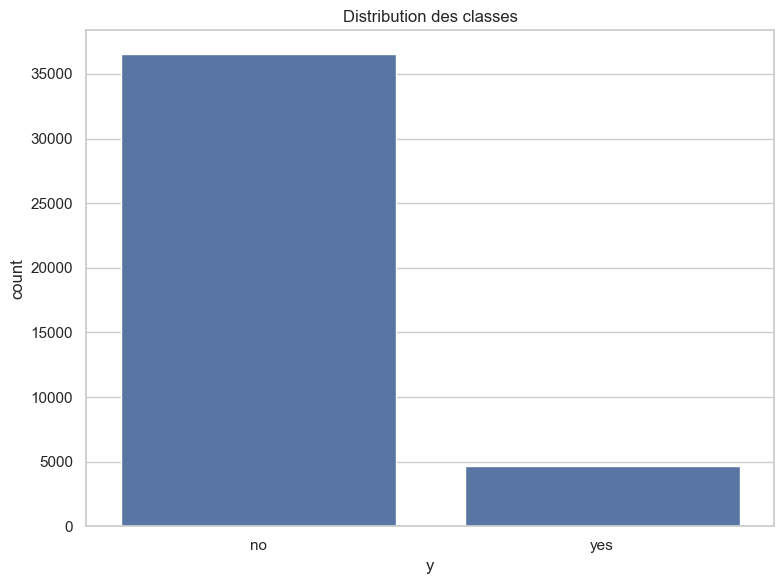

In [15]:
def analyze_class_balance(df, target_col, fig_name, transparent=False):
    """
    Analyse et visualise la distribution des classes
    """
    print_step('Analyse de la variable de sortie : ' + target_col)
    # Distribution des classes
    class_distribution = df[target_col].value_counts()
    class_distribution = class_distribution.sort_index()
    print(bold("Distribution des classes :"))
    print(class_distribution)

    # Calcul du ratio
    ratio = class_distribution.max() / class_distribution.min()
    print("\n" + bold('Ratio classe majoritaire/minoritaire : ') + f'{ratio:.2f}')

    taux = 100 * (df[target_col] == 'yes').mean()
    print(bold('Taux de souscription : ') + f'{taux:.2f} %')
    print(bold("Accuracy d'un modèle répondant toujours 'no' : ")
          + f'{100 - taux:.2f} %')

    # Visualisation
    plt.figure(figsize=(8, 6))
    sns.countplot(data=df, x=target_col)
    plt.title('Distribution des classes')
    plt.tight_layout()
    plt.savefig(fig_name, dpi=100, transparent=transparent)
    plt.show()
    return class_distribution


class_distribution = analyze_class_balance(
    df, TARGET_COL, DOSSIER_FIGURES + 'balance.png')

Le ratio est d'environ 1 pour 8. Deux conséquences, à retenir pour les étapes
suivantes :

1. **L'accuracy est inutilisable comme métrique de décision.** Un modèle qui
   répond systématiquement « non » atteint près de 89 % sans aucune valeur.
2. **Le rééquilibrage de l'étape 3 est justifié par la mesure**, et non par
   habitude. La fonction `rebalance_classes` du TD3 s'appliquera ici.

## 6. Variables catégorielles

Fonction ajoutée : le jeu *winequality* du TD2 ne contenait que des variables
numériques. On relève ici la cardinalité, la modalité dominante et l'effectif
le plus faible, qui détermine les regroupements à prévoir.

In [16]:
def analyze_categorical(df, target_col):
    """
    Décrit les variables catégorielles : cardinalité, modalité dominante,
    effectif minimal et taux de manquants
    """
    print_step('Analyse des variables catégorielles')
    cat_cols = [c for c in df.select_dtypes(include='object').columns if c != target_col]

    lignes = []
    for col in cat_cols:
        vc = df[col].value_counts()
        lignes.append({
            'variable': col,
            'modalites': df[col].nunique(),
            'dominante': vc.index[0],
            'part_dominante': round(100 * vc.iloc[0] / len(df), 1),
            'effectif_min': int(vc.min()),
            'unknown': int((df[col] == 'unknown').sum())})

    resume = pd.DataFrame(lignes).sort_values('modalites', ascending=False)
    print(resume.to_string(index=False))
    return cat_cols, resume


cat_cols, resume_cat = analyze_categorical(df, TARGET_COL)


*** Analyse des variables catégorielles ***

   variable  modalites         dominante  part_dominante  effectif_min  unknown
        job         12            admin.            25.3           330      330
      month         10               may            33.4           182        0
  education          8 university.degree            29.5            18     1731
day_of_week          5               thu            20.9          7827        0
    marital          4           married            60.5            80       80
    default          3                no            79.1             3     8597
       loan          3                no            82.4           990      990
    housing          3               yes            52.4           990      990
   poutcome          3       nonexistent            86.3          1373        0
    contact          2          cellular            63.5         15044        0


In [17]:
print_step('Modalités à faible effectif')
for col in cat_cols:
    vc = df[col].value_counts()
    rares = vc[vc < 500]
    if len(rares) > 0:
        print("\n" + bold('Colonne : ') + cyan(col))
        print(rares.to_string())


*** Modalités à faible effectif ***


Colonne : job
job
unknown    330

Colonne : marital
marital
unknown    80

Colonne : education
education
illiterate    18

Colonne : default
default
yes    3

Colonne : month
month
dec    182


`education = illiterate` ne compte que 18 observations et `default = yes`
seulement 3. Ces modalités devront être regroupées à l'étape 3 : un effectif
aussi faible ne permet aucune estimation fiable.

## 7. Analyse bivariée : relation à la cible

Reprise de l'idiome de `advanced_visualization` du TD2 — une boîte à moustaches
par variable numérique, découpée selon la classe.


*** Analyse bivariée : variables numériques et classe ***

      variable  moyenne_yes  moyenne_no  d_cohen
      duration      553.191     220.845    1.402
   nr.employed     5095.116    5176.167   -1.200
         pdays      792.036     984.114   -1.087
     euribor3m        2.123       3.811   -1.023
  emp.var.rate       -1.233       0.249   -0.989
      previous        0.493       0.132    0.748
cons.price.idx       93.354      93.604   -0.435
      campaign        2.052       2.633   -0.210
 cons.conf.idx      -39.790     -40.593    0.174
           age       40.913      39.911    0.096


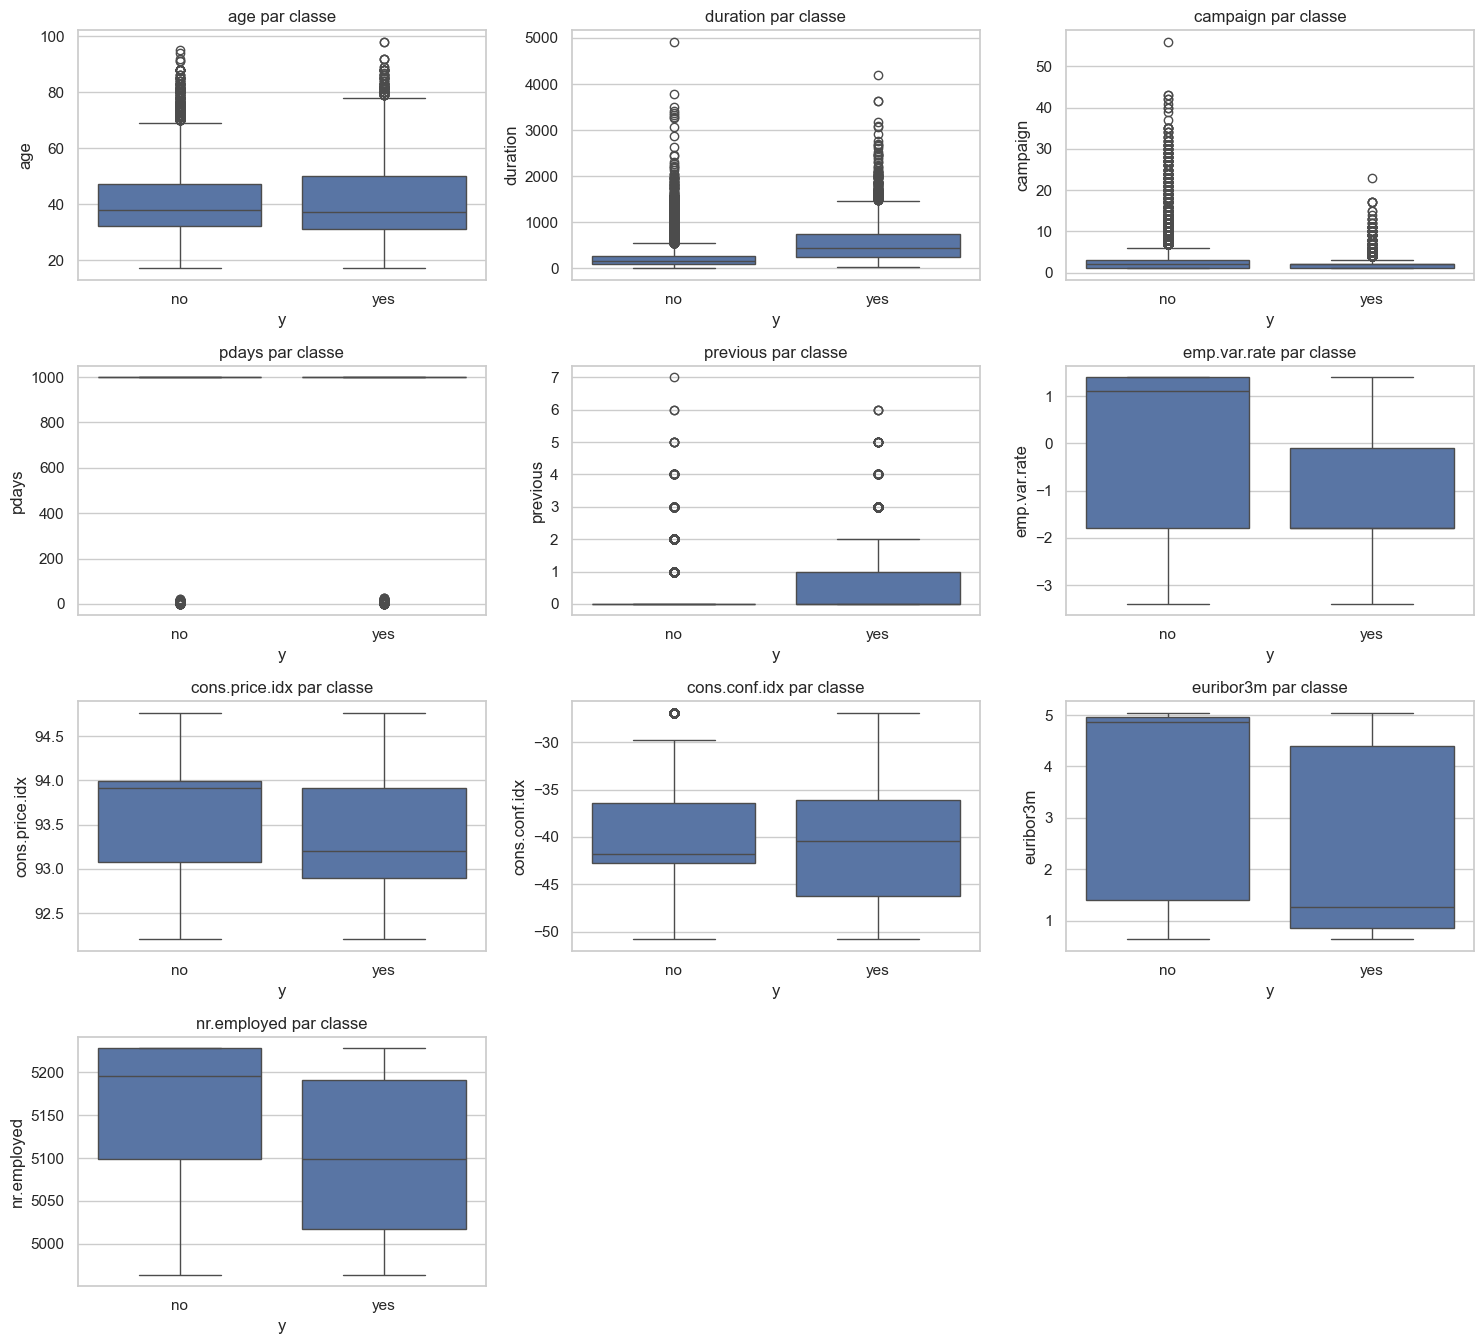

Fichier ../figures/bivarie_numerique.png enregistré.


In [18]:
def analyze_target_relation_numeric(df, target_col, numeric_cols, fig_name,
                                    transparent=False):
    """
    Compare la distribution de chaque variable numérique selon la classe,
    et quantifie l'écart par le d de Cohen
    """
    print_step('Analyse bivariée : variables numériques et classe')

    y_bin = (df[target_col] == 'yes')

    def cohen_d(a, b):
        na, nb = len(a), len(b)
        s = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
        return (a.mean() - b.mean()) / s if s else 0.0

    lignes = []
    for col in numeric_cols:
        oui, non = df.loc[y_bin, col], df.loc[~y_bin, col]
        lignes.append({
            'variable': col,
            'moyenne_yes': round(oui.mean(), 3),
            'moyenne_no': round(non.mean(), 3),
            'd_cohen': round(cohen_d(oui, non), 3)})

    resume = pd.DataFrame(lignes)
    resume['abs_d'] = resume.d_cohen.abs()
    resume = resume.sort_values('abs_d', ascending=False).drop(columns='abs_d')
    print(resume.to_string(index=False))

    # Visualisation
    n = len(numeric_cols)
    fig, axes = plt.subplots((n + 2) // 3, 3, figsize=(15, 3.4 * ((n + 2) // 3)))
    for ax, col in zip(axes.ravel(), numeric_cols):
        sns.boxplot(data=df, x=target_col, y=col, ax=ax)
        ax.set_title(f'{col} par classe')
    for ax in axes.ravel()[n:]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.savefig(fig_name, dpi=100, transparent=transparent)
    plt.show()
    print(f'Fichier {fig_name} enregistré.')
    return resume


resume_num_biv = analyze_target_relation_numeric(
    df, TARGET_COL, list(numeric_cols), DOSSIER_FIGURES + 'bivarie_numerique.png')

**Attention à la lecture de `pdays`.** Son d de Cohen est élevé, mais il compare
deux mélanges de durées et de sentinelles. Il n'est pas interprétable avant le
recodage de l'étape 3. La lecture correcte est la suivante :

In [19]:
y_bin = (df[TARGET_COL] == 'yes')

print_step('Lecture correcte de pdays : trois groupes, et non deux')
lectures = [
    (df.pdays != 999, 'Recontacté, délai connu'),
    ((df.pdays == 999) & (df.previous >= 1), 'Recontacté, délai inconnu'),
    (df.previous == 0, 'Jamais contacté'),
]
for masque, libelle in lectures:
    print(bold(f'{libelle:28s}')
          + f' : {int(masque.sum()):6d} clients, '
          + f'{100 * y_bin[masque].mean():5.2f} % de souscription')
print("\n" + bold('Base de référence : ') + f'{100 * y_bin.mean():.2f} %')


*** Lecture correcte de pdays : trois groupes, et non deux ***

Recontacté, délai connu      :   1515 clients, 63.83 % de souscription
Recontacté, délai inconnu    :   4110 clients, 12.94 % de souscription
Jamais contacté              :  35563 clients,  8.83 % de souscription

Base de référence : 11.27 %


L'écart est considérable. Un client déjà recontacté souscrit environ sept fois
plus souvent. C'est la variable la plus prometteuse une fois recodée.

### Le cas de l'âge

Le d de Cohen de `age` est proche de zéro, ce qui suggérerait une variable sans
intérêt. Un découpage en tranches montre l'inverse.


*** Taux de souscription par tranche d'âge ***

age
(16, 25]    20.9
(25, 35]    11.7
(35, 45]     8.5
(45, 55]     8.7
(55, 60]    12.2
(60, 99]    45.5


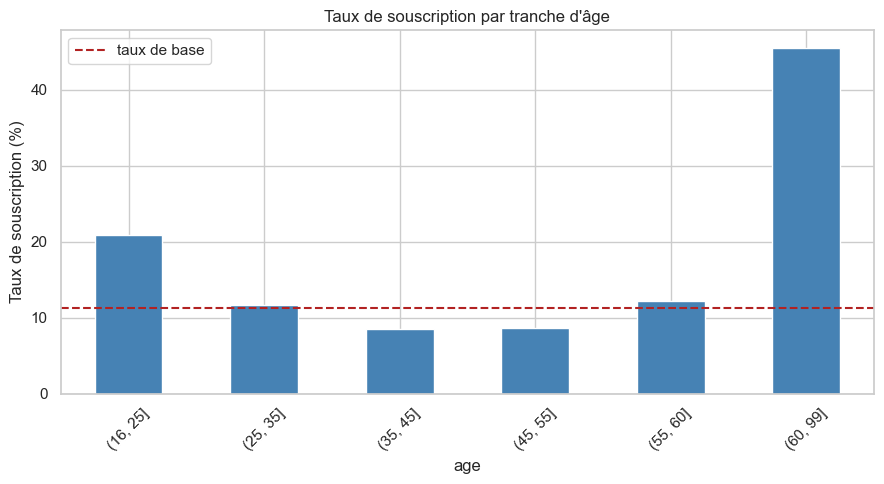

In [20]:
print_step("Taux de souscription par tranche d'âge")
tranches = pd.cut(df.age, [16, 25, 35, 45, 55, 60, 99])
taux_age = (100 * df.assign(_y=y_bin).groupby(tranches, observed=True)['_y'].mean()).round(1)
print(taux_age.to_string())

plt.figure(figsize=(9, 5))
taux_age.plot(kind='bar', color='steelblue')
plt.axhline(100 * y_bin.mean(), color='firebrick', linestyle='--',
            label='taux de base')
plt.title("Taux de souscription par tranche d'âge")
plt.ylabel('Taux de souscription (%)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig(DOSSIER_FIGURES + 'bivarie_age.png', dpi=100)
plt.show()

La relation est **en U** : les moins de 25 ans et les plus de 60 ans souscrivent
beaucoup plus que les tranches intermédiaires. Une statistique de résumé
bivariée comme le d de Cohen écrase complètement ce comportement.

C'est l'enseignement méthodologique principal de cette étape : **un indicateur
global peut masquer le signal le plus fort du jeu de données.**

### Variables catégorielles et cible

Pour chaque modalité, on compare le taux de souscription au taux de base de
11,27 %. Le V de Cramér mesure l'intensité du lien.


*** Analyse bivariée : variables catégorielles et classe ***

   variable  V_cramer
   poutcome     0.320
      month     0.274
        job     0.153
    contact     0.145
    default     0.099
  education     0.068
    marital     0.055
day_of_week     0.025
    housing     0.012
       loan     0.005

Colonne : poutcome
             taux_%  effectif
poutcome                     
success        65.1      1373
failure        14.2      4252
nonexistent     8.8     35563

Colonne : month
       taux_%  effectif
month                  
mar      50.5       546
dec      48.9       182
sep      44.9       570
oct      43.9       718
apr      20.5      2632
aug      10.6      6178
jun      10.5      5318
nov      10.1      4101
jul       9.0      7174
may       6.4     13769

Colonne : job
               taux_%  effectif
job                            
student          31.4       875
retired          25.2      1720
unemployed       14.2      1014
admin.           13.0     10422
unknown      

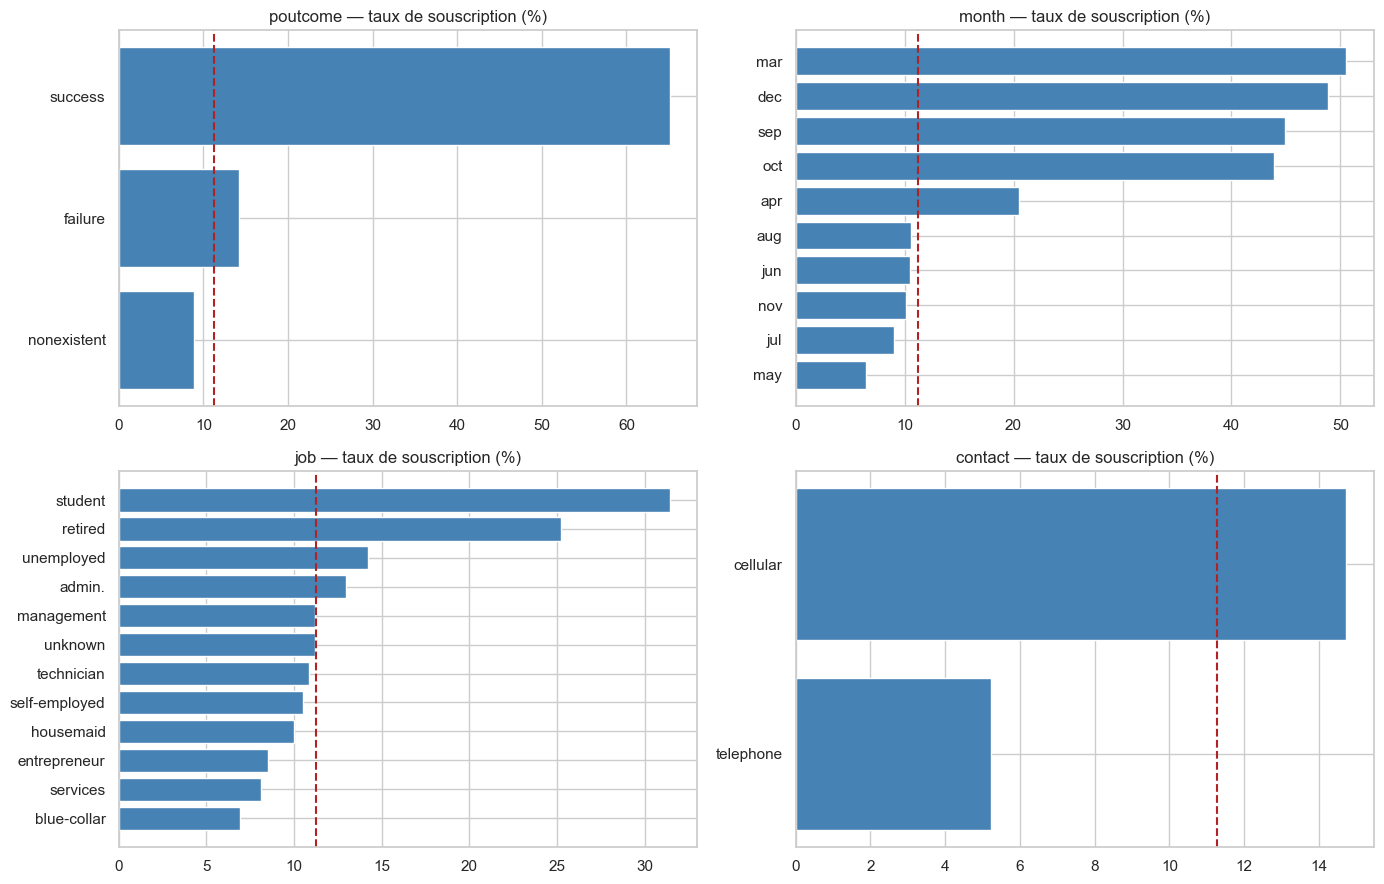

Fichier ../figures/bivarie_categoriel.png enregistré.


In [21]:
def analyze_target_relation_categorical(df, target_col, cat_cols, fig_name,
                                        transparent=False):
    """
    Mesure le lien entre chaque variable catégorielle et la cible (V de Cramér)
    et affiche le taux de souscription par modalité
    """
    print_step('Analyse bivariée : variables catégorielles et classe')
    y_bin = (df[target_col] == 'yes')

    def cramers_v(x, yb):
        tab = pd.crosstab(x, yb)
        if tab.shape[0] < 2:
            return 0.0
        total = tab.to_numpy().sum()
        exp = np.outer(tab.sum(axis=1), tab.sum(axis=0)) / total
        chi2 = ((tab.to_numpy() - exp) ** 2 / exp).sum()
        return float(np.sqrt((chi2 / total) / (min(tab.shape) - 1)))

    resume = pd.DataFrame(
        [{'variable': c, 'V_cramer': round(cramers_v(df[c], y_bin), 3)}
         for c in cat_cols]).sort_values('V_cramer', ascending=False)
    print(resume.to_string(index=False))

    # Détail des quatre variables les plus liées
    top = resume.variable.head(4).tolist()
    for col in top:
        g = df.assign(_y=y_bin).groupby(col, observed=True)['_y'].agg(['mean', 'size'])
        g['taux_%'] = (100 * g['mean']).round(1)
        g = g[['taux_%', 'size']].rename(columns={'size': 'effectif'})
        print("\n" + bold('Colonne : ') + cyan(col))
        print(g.sort_values('taux_%', ascending=False).to_string())

    # Visualisation
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    taux_base = 100 * y_bin.mean()
    for ax, col in zip(axes.ravel(), top):
        g = (100 * df.assign(_y=y_bin).groupby(col, observed=True)['_y'].mean()
             ).sort_values()
        ax.barh(g.index.astype(str), g.to_numpy(), color='steelblue')
        ax.axvline(taux_base, color='firebrick', linestyle='--')
        ax.set_title(f'{col} — taux de souscription (%)')
    plt.tight_layout()
    plt.savefig(fig_name, dpi=100, transparent=transparent)
    plt.show()
    print(f'Fichier {fig_name} enregistré.')
    return resume


resume_cat_biv = analyze_target_relation_categorical(
    df, TARGET_COL, cat_cols, DOSSIER_FIGURES + 'bivarie_categoriel.png')

`poutcome` est la variable catégorielle la plus liée à la cible : un succès lors
d'une campagne précédente fait passer le taux de souscription de 11 % à environ
65 %. Elle ne concerne cependant qu'un nombre réduit de clients, ce qui limite
sa portée.

`job` confirme la lecture de l'âge : étudiants et retraités souscrivent bien
davantage que les actifs.

## 8. La variable `duration`

Le fichier `bank-additional-names.txt` fourni avec le jeu contient
l'avertissement suivant :

> *duration: last contact duration, in seconds (numeric). **Important note:**
> this attribute highly affects the output target (e.g., if duration=0 then
> y="no"). Yet, the duration is not known before a call is performed. Also,
> after the end of the call y is obviously known. Thus, this input should only
> be included for benchmark purposes and should be discarded if the intention
> is to have a realistic predictive model.*

La durée de l'appel n'existe pas au moment où l'on décide de passer cet appel.
L'inclure revient à utiliser une information du futur : c'est une **fuite de
données**. Nous l'écartons donc, et nous mesurons ci-dessous ce qu'elle apporte
artificiellement — cette mesure sera reprise dans le rapport.


*** Relation entre duration et la cible ***

Durée moyenne des appels aboutissant à une souscription : 553 s
Durée moyenne des autres appels : 221 s


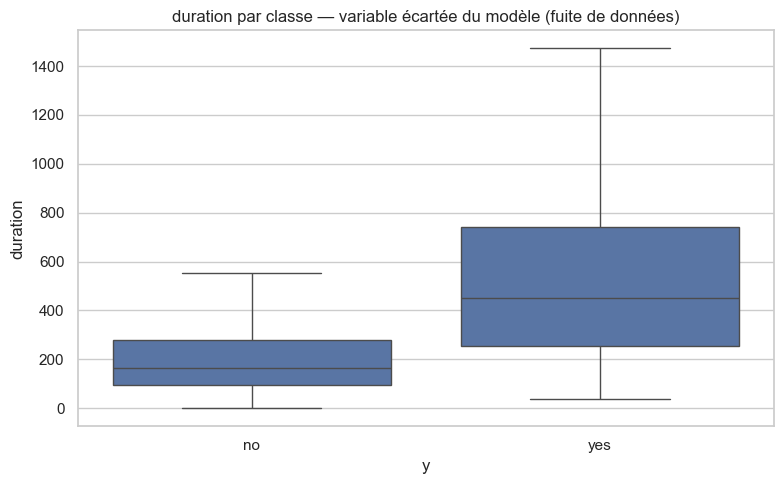

In [22]:
print_step('Relation entre duration et la cible')
print(bold('Durée moyenne des appels aboutissant à une souscription : ')
      + f"{df.loc[y_bin, 'duration'].mean():.0f} s")
print(bold('Durée moyenne des autres appels : ')
      + f"{df.loc[~y_bin, 'duration'].mean():.0f} s")

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x=TARGET_COL, y='duration', showfliers=False)
plt.title("duration par classe — variable écartée du modèle (fuite de données)")
plt.tight_layout()
plt.savefig(DOSSIER_FIGURES + 'fuite_duration.png', dpi=100)
plt.show()

## 9. Synthèse de l'étape 2

Les constats ci-dessous ferment l'étape 2 et ouvrent l'étape 3. Aucune donnée
n'a été modifiée dans ce notebook.

In [23]:
print_step("Synthèse de l'étape 2")

synthese = pd.DataFrame([
    ('Volumétrie', f'{df.shape[0]} lignes, {df.shape[1]} colonnes',
     'Aucune action'),
    ('Doublons', f'{df.duplicated().sum()} lignes identiques',
     'À trancher : clients distincts ou re-saisies'),
    ('Manquants', "0 détecté par isna(), mais 'unknown' sur 6 variables",
     'Imputation ou modalité à part : étape 3'),
    ('Sentinelle',
     f'pdays = 999 sur {100 * (df.pdays == 999).mean():.1f} % des lignes, dont '
     f'{int(((df.pdays == 999) & (df.previous >= 1)).sum())} contacts réels',
     'Recodage en trois modalités, indicateur bâti sur previous : étape 3'),
    ('Aberrants', 'Signalés sur campaign et previous',
     'Conservés : comportements réels'),
    ('Déséquilibre', f'{100 * y_bin.mean():.2f} % de souscriptions',
     'Rééquilibrage : étape 3'),
    ('Faibles effectifs', 'education=illiterate (18), default=yes (3)',
     'Regroupement : étape 3'),
    ('Fuite', "duration connue seulement après l'appel",
     'Variable écartée du modèle'),
], columns=['constat', 'mesure', 'suite'])

print(synthese.to_string(index=False))


*** Synthèse de l'étape 2 ***

          constat                                                      mesure                                                               suite
       Volumétrie                                   41188 lignes, 21 colonnes                                                       Aucune action
         Doublons                                        12 lignes identiques                        À trancher : clients distincts ou re-saisies
        Manquants        0 détecté par isna(), mais 'unknown' sur 6 variables                             Imputation ou modalité à part : étape 3
       Sentinelle pdays = 999 sur 96.3 % des lignes, dont 4110 contacts réels Recodage en trois modalités, indicateur bâti sur previous : étape 3
        Aberrants                           Signalés sur campaign et previous                                     Conservés : comportements réels
     Déséquilibre                                    11.27 % de souscriptions               

In [24]:
# Export des tableaux pour le rapport
synthese.to_csv('../sorties/etape2_synthese.csv', index=False, sep=';')
resume_unknown.to_csv('../sorties/etape2_manquants.csv', sep=';')
resume_outliers.to_csv('../sorties/etape2_outliers.csv', index=False, sep=';')
# Le d de Cohen de pdays compare deux mélanges de délais et de sentinelles :
# il n'est pas interprétable en l'état (voir la section consacrée à pdays).
remarques = {
    'pdays': 'non interprétable : mélange sentinelle / délais réels',
    'duration': 'fuite de données : variable écartée du modèle',
    'age': 'd faible mais relation en U : voir figure bivarie_age',
}
resume_num_biv['remarque'] = resume_num_biv['variable'].map(remarques).fillna('')
resume_num_biv.to_csv('../sorties/etape2_bivarie_numerique.csv', index=False, sep=';')
resume_cat_biv.to_csv('../sorties/etape2_bivarie_categoriel.csv', index=False, sep=';')

print_step('Sauvegarde')
print(bold('Tableaux exportés dans ') + '../sorties/')
print('\nLe notebook 02_preparation reprend à partir du fichier brut et produit')
print("output.csv et params.pkl, selon le contrat de passage du TD2 vers le TD3.")


*** Sauvegarde ***

Tableaux exportés dans ../sorties/

Le notebook 02_preparation reprend à partir du fichier brut et produit
output.csv et params.pkl, selon le contrat de passage du TD2 vers le TD3.
